# <a id='toc1_'></a>[XGBoosting](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Floresta Aleatória](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Separação treino e teste - validação cruzada](#toc1_2_1_)    
    - [Aplicando a Árvore de Decisão](#toc1_2_2_)    
    - [Otimização de hiperparâmetros](#toc1_2_3_)    
    - [Analisando os resultados](#toc1_2_4_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos implementar o modelo de XGBoosting ao nosso dataset. Depois de implementá-lo, também vamos otimizar seus hiperparâmetros e comparar os resultados obtidos com outros modelos.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos iniciar coletando e tratando os dados que iremos utilizar, como feito no notebook [01.A - Baseline](01.A%20-%20Baseline.ipynb). Dessa vez, como vamos realizar a otimização, vamos dividir nosso conjunto em dados de treino e dados de teste.

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

ATTRIBUTES = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "magnitude_type",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "land_fraction",
    "origin_plate"
]

TARGET = [
    "amplitude_factor_log10"
]

df_earthquakes = pd.read_csv("../00 - Coleta e Tratamento de Dados/Data/earthquake_dataset_treated.csv")

X = df_earthquakes.reindex(ATTRIBUTES, axis=1)
y = df_earthquakes.reindex(TARGET, axis=1)

CATEGORICAL_ATTRIBUTES = ["magnitude_type", "origin_plate"]
NUMERICAL_ATTRIBUTES = [
    column for column in X.columns
    if column not in CATEGORICAL_ATTRIBUTES
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_ATTRIBUTES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_ATTRIBUTES
        )
    ]
)

### <a id='toc1_2_1_'></a>[Separação treino e teste - validação cruzada](#toc0_)

Para dividir os dados de treino e teste, de forma à estimar as métricas dos modelos induzidos de uma forma mais confiável, iremos utilizar a técnica de **Validação cruzada**. Mais especificamente, aplicaremos o método $k$-fold, a partir da biblioteca `scikit-learn`.

In [2]:
from sklearn.model_selection import KFold

NUM_FOLDS = 10
RANDOM_STATE = 424242

TEST_SIZE = 0.1

df_earthquakes = df_earthquakes.reindex(ATTRIBUTES + TARGET, axis=1)

y_bins = pd.qcut(
    y.values.ravel(),
    q=5,
    labels=False,
    duplicates="drop"
)

idx = df_earthquakes.index
train_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_bins)

df_train = df_earthquakes.iloc[train_idx]
df_test = df_earthquakes.iloc[test_idx]

X_train = df_train.reindex(ATTRIBUTES, axis=1)
y_train = df_train.reindex(TARGET, axis=1)

X_test = df_test.reindex(ATTRIBUTES, axis=1)
y_test = df_test.reindex(TARGET, axis=1)

kf = KFold(NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

### <a id='toc1_2_2_'></a>[Aplicando o XGBoosting](#toc0_)

Vamos utilizar o `XGBoosting` da biblioteca **xgboost** para induzir nosso modelo, de acordo com a referência [2].

A métrica que utilizaremos de referência será o RMSE, que é a raiz do erro quadrático médio das previsões do nosso modelo.

In [3]:
# !pip install xgboost

As métricas foram:
 0 - 0.4948115348815918
 1 - 0.39395636320114136
 2 - 0.5917511582374573
 3 - 0.6962380409240723
 4 - 0.3185670077800751
 5 - 0.19935591518878937
 6 - 0.39160528779029846
 7 - 0.6171560883522034
 8 - 0.5171551704406738
 9 - 0.6315136551856995


A média das métricas é de: 0.4852110221982002


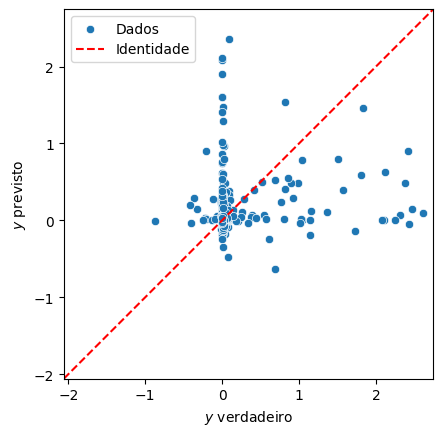

In [5]:
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error
import seaborn as sns
import numpy as np

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(
            objective="reg:squarederror",
            random_state=RANDOM_STATE
        ))
    ]
)

def test_kf(model, X=X, y=y, kf=kf, plot=True):
    metrics = []
    true_y = []
    pred_y = []

    for train_idx, test_idx in kf.split(X):

        X_train_, X_test_ = X.iloc[train_idx], X.iloc[test_idx]
        y_train_, y_test_ = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train_, y_train_.values.ravel())

        true_y_ = y_test_
        pred_y_ = model.predict(X_test_)
        
        true_y.append(true_y_)
        pred_y.append(pred_y_)

        RMSE = root_mean_squared_error(true_y_, pred_y_)

        metrics.append(RMSE)

    if plot:
        print("As métricas foram:\n", *[f"{i} - {metric}\n" for i, metric in enumerate(metrics)])
        print()
        print("A média das métricas é de:", np.mean(metrics))

        true_y = np.concatenate(true_y).ravel()
        pred_y = np.concatenate(pred_y).ravel()

        min_val = min(true_y.min(), pred_y.min())
        max_val = max(true_y.max(), pred_y.max())

        interval = [min_val * 0.95, max_val * 1.05]

        ax = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
        ax.plot(interval, interval, "r--", label="Identidade")

        ax.set(
            xlabel="$y$ verdadeiro",
            ylabel="$y$ previsto",
            xlim=interval,
            ylim=interval,
            aspect="equal",
        )
        ax.legend();
    
    return metrics
    
xgb_metrics = test_kf(xgb_model)

Podemos ver que já houve uma tentativa diferente do modelo para tentar prever cada uma das ampitudes de uma forma diferente, se concentrado em acertos no meio e dispersando em valores maiores. Entretanto, o modelo utilizado parece não ter atingido uma complexidade suficiente para descrever corretamente o padrão dos dados, praticamente se igualando ao baseline. Vamos ver como ele se comporta ao otimizar os os hiperparâmetros utilizando o optuna.

### <a id='toc1_2_3_'></a>[Otimização de hiperparâmetros](#toc0_)

Para a otimização do modelo, serão avaliados os seguintes parâmetros:

- `n_estimators`: varia de 50 a 300, definindo a quantidade de árvores adicionadas sequencialmente ao modelo.
- `learning_rate`: varia de 0,01 a 0,3, controlando a contribuição de cada árvore para a previsão final. A busca será realizada em escala logarítmica, permitindo uma exploração mais adequada de diferentes ordens de grandeza.
- `max_depth`: varia de 2 a 10, controlando a profundidade máxima das árvores e, consequentemente, sua complexidade.
- `min_child_weight`: varia de 1 a 10, controlando a quantidade mínima de informação necessária para que uma divisão seja realizada, contribuindo para evitar árvores excessivamente complexas.
- `subsample`: varia de 0,5 a 1,0, definindo a fração das amostras utilizada na construção de cada árvore.
- `colsample_bytree`: varia de 0,5 a 1,0, definindo a fração dos atributos considerada na construção de cada árvore.

In [ ]:
def create_model_instance(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.3, log=True
        ),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.5, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.5, 1.0
        ),
        "objective"="reg:squarederror",
        "random_state"=RANDOM_STATE
    }
    
    
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(**params))
    ]
    
    
    xgb_model = Pipeline(steps)
    
    return xgb_model

Agora, vamos definir a função objetivo, que vai medir a métrica do modelo.

In [7]:
def objective_function(trial, X, y, kf, num_folds):
    model = create_model_instance(trial)
    
    metrics = test_kf(model, X, y, kf, plot=False)
    
    return np.mean(metrics)

Então, vamos criar o objeto de estudo, que será responsável por buscar os melhores hiperparâmetros do espaço delimitado

In [8]:
from optuna import create_study, delete_study, get_all_study_summaries

STUDY_NAME = "Studies/xgb_tiamat"
STORAGE = f"sqlite:///{STUDY_NAME}.db"

studies = get_all_study_summaries(storage=STORAGE)

if any(study.study_name == STUDY_NAME for study in studies):
    delete_study(
        study_name=STUDY_NAME,
        storage=STORAGE
    )

study_obj = create_study(
    direction="minimize",
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
)

[I 2026-11-16 10:25:00,700] A new study created in RDB with name: Studies/xgb_tiamat


Utilizando o funtools. podemos criar nossa função objetiva parcial

In [9]:
from functools import partial

partial_objective_function = partial(
    objective_function, X=X_train, y=y_train, kf=kf, num_folds=NUM_FOLDS
)

E, por fim, otimizamos o estudo a partir do método `optimize`. Vamos utilizar um número de tentativas inicial como 100.

In [10]:
N_TRIALS = 100

study_obj.optimize(partial_objective_function, n_trials=N_TRIALS)

[I 2026-11-16 10:25:11,805] Trial 0 finished with value: 0.417382650077343 and parameters: {'n_estimators': 110, 'learning_rate': 0.025056738982870357, 'max_depth': 3, 'min_child_weight': 2, 'subsample': 0.9036170071518169, 'colsample_bytree': 0.8268255779316356}. Best is trial 0 with value: 0.417382650077343.
[I 2026-11-16 10:25:14,054] Trial 1 finished with value: 0.5035057872533798 and parameters: {'n_estimators': 251, 'learning_rate': 0.25953185694165026, 'max_depth': 7, 'min_child_weight': 10, 'subsample': 0.8051667266356994, 'colsample_bytree': 0.7406168054324427}. Best is trial 0 with value: 0.417382650077343.
[I 2026-11-16 10:25:15,709] Trial 2 finished with value: 0.4987828880548477 and parameters: {'n_estimators': 193, 'learning_rate': 0.17377504597097257, 'max_depth': 6, 'min_child_weight': 2, 'subsample': 0.8299923381381241, 'colsample_bytree': 0.8886582401953513}. Best is trial 0 with value: 0.417382650077343.
[I 2026-11-16 10:25:16,263] Trial 3 finished with value: 0.4239

### <a id='toc1_2_4_'></a>[Analisando os resultados](#toc0_)

Vamos observar os resultados do estudo

In [11]:
df = study_obj.trials_dataframe()

df

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_subsample,system_attrs_tpe:relative_params:0,state
0,0,0.417383,2026-11-16 10:25:10.978084,2026-11-16 10:25:11.771248,0 days 00:00:00.793164,0.826826,0.025057,3,2,110,0.903617,NaN,COMPLETE
1,1,0.503506,2026-11-16 10:25:11.812715,2026-11-16 10:25:14.036047,0 days 00:00:02.223332,0.740617,0.259532,7,10,251,0.805167,NaN,COMPLETE
2,2,0.498783,2026-11-16 10:25:14.062136,2026-11-16 10:25:15.693127,0 days 00:00:01.630991,0.888658,0.173775,6,2,193,0.829992,NaN,COMPLETE
3,3,0.423992,2026-11-16 10:25:15.717612,2026-11-16 10:25:16.246854,0 days 00:00:00.529242,0.846330,0.052271,3,7,79,0.603792,NaN,COMPLETE
4,4,0.494744,2026-11-16 10:25:16.273479,2026-11-16 10:25:17.963152,0 days 00:00:01.689673,0.987883,0.220701,8,6,157,0.774505,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.407939,2026-11-16 10:26:36.294059,2026-11-16 10:26:37.124199,0 days 00:00:00.830140,0.706327,0.010822,5,6,86,0.573510,"{""colsample_bytree"": 0.7063266651701898, ""lear...",COMPLETE
96,96,0.407961,2026-11-16 10:26:37.156722,2026-11-16 10:26:38.153220,0 days 00:00:00.996498,0.647040,0.011397,6,7,87,0.528785,"{""colsample_bytree"": 0.6470396628313277, ""lear...",COMPLETE
97,97,0.409015,2026-11-16 10:26:38.181120,2026-11-16 10:26:38.853791,0 days 00:00:00.672671,0.605226,0.010346,5,7,62,0.568146,"{""colsample_bytree"": 0.6052263740965066, ""lear...",COMPLETE
98,98,0.409028,2026-11-16 10:26:38.882951,2026-11-16 10:26:39.688458,0 days 00:00:00.805507,0.634659,0.010933,4,7,99,0.603495,"{""colsample_bytree"": 0.6346590142755938, ""lear...",COMPLETE


O melhor resultado pode ser obtido através do atributo `best_trial`

In [12]:
best_trial = study_obj.best_trial

print(f"Número do melhor trial: {best_trial.number}")
print(f"Parâmetros do melhor trial: {best_trial.params}")

Número do melhor trial: 85
Parâmetros do melhor trial: {'n_estimators': 82, 'learning_rate': 0.011762139941916242, 'max_depth': 5, 'min_child_weight': 7, 'subsample': 0.551675785815139, 'colsample_bytree': 0.6352102860996686}


Vamos criar um modelo com o melhor conjunto de hiperparâmetros encontrados e checar seu desempenho.

O RMSE calculado é de: 0.3855485332898776


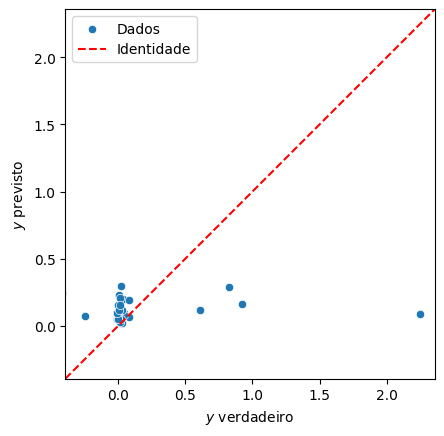

In [13]:
model = create_model_instance(best_trial)
model.fit(X_train, y_train.values.ravel())

true_y = np.asarray(y_test).ravel()
pred_y = np.asarray(model.predict(X_test)).ravel()

RMSE = root_mean_squared_error(true_y, pred_y)

min_val = min(true_y.min(), pred_y.min())
max_val = max(true_y.max(), pred_y.max())

interval = [min_val * 0.95, max_val * 1.05]

eixo = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
eixo.plot(interval, interval, "r--", label="Identidade")

eixo.set(
    xlabel="$y$ verdadeiro",
    ylabel="$y$ previsto",
    xlim=interval,
    ylim=interval,
    aspect="equal",
)
eixo.legend();

print(f"O RMSE calculado é de: {RMSE}")

Aparentemente, o modelo de XGBoosting otimizado conseguiu um RMSE com cerca de 0.040 pontos a menos se comparado ao modelo baseline, prevendo melhor os valores próximos de 0, mas ainda assim com uma certa dispersão.

Talvez uma análise mais aprofundada dos hiperparâmetros poderia aprimorar essa eficácia.

Vamos ver como ficou a importância dos parâmetros de busca de acordo com o optuna

In [16]:
import optuna.visualization as vis 

vis.plot_param_importances(study_obj)

Pelo gráfico, vemos como a profundidade máxima é o hiperparâmetro mais importantes, seguido da fração de amostras utilizada para a construção da próxima árvore e a quantidade mínima de informações pre fazer o split.

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Sendo assim, nosso modelo de XGBoosting apresentou um RMSE inferior ao obtido pelo modelo baseline. Entretanto, nem todo o espaço de dados foi coberto de forma adequada, e o desempenho demonstrado foi inferior ao do modelo de Gradient Boosting.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 1.1 - Tratamento de dados com pandas*. Campinas: Ilum Escola de Ciência, 2026.
2. **SOUZA, Matheus Luiz Mendes de**. *T26 - XGBoost*. Campinas: ILUM Escola de Ciência, 2026. Disponível em: <https://github.com/drcassar/biblioteca_real/tree/main/Aprendizado%20de%20M%C3%A1quina/XGBoost/T26%20-%20Matheus%20Luiz%20Mendes%20de%20Souza>.
3. **CASSAR, Daniel R.** *ATP-203 7.1 - Otimização de hiperparâmetros com optuna*. Campinas: Ilum Escola de Ciência, 2026.